Phase 2 : Constructing the KG

In [7]:
#. Build the Knowledge Graph

def build_knowledge_graph(gnp_pairs, csp_pairs):
    """Construct the expanded Hindi gender-bias KG and JSON triplet store."""
    G = nx.DiGraph()
    triplets = []


    for dimension, counterclaim in DIMENSION_COUNTERCLAIMS.items():
        dimension_id = f"dimension:{dimension}"
        counterclaim_id = f"counterclaim:{dimension}"

        G.add_node(
            dimension_id,
            label=dimension,
            node_type="StereotypeDimension",
        )
        G.add_node(
            counterclaim_id,
            label=counterclaim,
            node_type="CounterClaim",
        )
        G.add_edge(
            dimension_id,
            counterclaim_id,
            relation="COUNTERED_BY",
        )

    print("Building GNP layer...")
    for pair in gnp_pairs:
        original = pair["original"]
        neutral = pair["neutral"]
        category = classify_gnp_category(original, neutral)
        grammatical_gender = detect_grammatical_gender(original)

        original_id = f"gendered:{original}"
        neutral_id = f"neutral:{neutral}"
        category_id = f"category:{category}"

        G.add_node(
            original_id,
            label=original,
            node_type="GenderedTerm",
            grammatical_gender=grammatical_gender,
        )
        G.add_node(neutral_id, label=neutral, node_type="NeutralTerm")
        G.add_node(category_id, label=category, node_type="StereotypeCategory")

        G.add_edge(original_id, neutral_id, relation="NEUTRAL_REPLACEMENT")
        G.add_edge(original_id, category_id, relation="BELONGS_TO_CATEGORY")

        if grammatical_gender in {"masculine_marked", "feminine_marked"}:
            rule_id = f"grammar_rule:{grammatical_gender}"
            G.add_node(
                rule_id,
                label=f"Hindi {grammatical_gender} morphology",
                node_type="GrammarRule",
            )
            G.add_edge(original_id, rule_id, relation="HAS_GRAMMATICAL_GENDER")

        triplets.append({
            "subject": original,
            "relation": "NEUTRAL_REPLACEMENT",
            "object": neutral,
            "category": category,
            "grammatical_gender": grammatical_gender,
        })

    print("Building CSP layer...")
    counterfactual_groups = defaultdict(list)
    for pair in csp_pairs:
        counterfactual_groups[pair["counterfactual"]].append(pair)

    print(
        f"  Found {len(counterfactual_groups)} unique inclusive rewrite templates"
    )

    for rule_index, (counterfactual, biased_variants) in enumerate(
        counterfactual_groups.items(), start=1
    ):
        counterfactual_id = f"counterfactual:{rule_index}"
        G.add_node(
            counterfactual_id,
            label=counterfactual,
            node_type="CounterfactualRule",
            rule_index=rule_index,
        )

        for variant in biased_variants:
            biased = variant["biased"]
            subject, subject_gender, predicate = extract_bias_predicate(biased)
            verb_gender, verb_marker = detect_verb_gender(predicate)
            dimensions = classify_stereotype_dimensions(biased)

            biased_id = f"biased:{variant['pair_id']}"
            G.add_node(
                biased_id,
                label=biased,
                node_type="BiasedSentence",
                subject_term=subject or "",
                subject_gender=subject_gender or "",
                predicate=predicate,
                verb_gender=verb_gender,
                stereotype_dimensions="|".join(dimensions),
            )

            G.add_edge(
                biased_id,
                counterfactual_id,
                relation="COUNTERFACTUAL_OF",
            )

            if subject:
                subject_id = f"subject:{subject}"
                G.add_node(
                    subject_id,
                    label=subject,
                    node_type="GenderedSubject",
                    gender=subject_gender,
                )
                G.add_edge(biased_id, subject_id, relation="HAS_SUBJECT")

            if verb_marker:
                mutation_id = f"mutation:{verb_gender}:{verb_marker}"
                G.add_node(
                    mutation_id,
                    label=verb_marker,
                    node_type="GrammarRule",
                    rule_type="verb_inflection",
                    gender=verb_gender,
                )
                G.add_edge(
                    biased_id,
                    mutation_id,
                    relation="TRIGGERS_MUTATION",
                )

            for dimension in dimensions:
                G.add_edge(
                    biased_id,
                    f"dimension:{dimension}",
                    relation="HAS_STEREOTYPE",
                )

            triplets.append({
                "subject": biased,
                "relation": "COUNTERFACTUAL_OF",
                "object": counterfactual,
                "subject_term": subject,
                "subject_gender": subject_gender,
                "predicate": predicate,
                "verb_gender": verb_gender,
                "verb_marker": verb_marker,
                "stereotype_dimensions": dimensions,
                "pair_id": variant["pair_id"],
            })

    print("Cross-linking GNP ↔ CSP dimensions...")
    for pair in gnp_pairs:
        if classify_gnp_category(pair["original"], pair["neutral"]) != "OCC":
            continue
        original_id = f"gendered:{pair['original']}"
        if G.has_node(original_id):
            G.add_edge(
                original_id,
                "dimension:Profession",
                relation="RELEVANT_TO_DIMENSION",
            )

    return G, triplets



In [8]:
def print_graph_stats(G):
    print("\n" + "=" * 60)
    print("HINDI GENDER BIAS KNOWLEDGE GRAPH — STATISTICS")
    print("=" * 60)

    node_types = Counter(
        data.get("node_type", "Unknown")
        for _, data in G.nodes(data=True)
    )
    edge_types = Counter(
        data.get("relation", "Unknown")
        for _, _, data in G.edges(data=True)
    )

    print(f"\nTotal nodes: {G.number_of_nodes()}")
    print(f"Total edges: {G.number_of_edges()}")

    print("\nNodes by type:")
    for node_type, count in sorted(node_types.items()):
        print(f"  {node_type:30s} {count:5d}")

    print("\nEdges by relation:")
    for edge_type, count in sorted(edge_types.items()):
        print(f"  {edge_type:30s} {count:5d}")

    dimensions = sorted(
        data["label"]
        for _, data in G.nodes(data=True)
        if data.get("node_type") == "StereotypeDimension"
    )
    print(f"\nStereotype dimensions: {dimensions}")

    gender_labels = Counter(
        data.get("grammatical_gender", "unknown")
        for _, data in G.nodes(data=True)
        if data.get("node_type") == "GenderedTerm"
    )
    print(f"\nGNP lexical gender-label distribution: {dict(gender_labels)}")

In [9]:
def main():
    print("Loading and validating datasets...")
    gnp_pairs, gnp_duplicates = load_gnp(GNP_PATH)
    csp_pairs, csp_duplicates = load_csp(CSP_PATH)

    print(f"  GNP unique pairs: {len(gnp_pairs)}")
    print(f"  GNP exact duplicates removed: {len(gnp_duplicates)}")
    print(f"  CSP unique pairs: {len(csp_pairs)}")
    print(f"  CSP exact duplicates removed: {len(csp_duplicates)}")

    if gnp_duplicates:
        print("\nRepeated GNP rows removed:")
        for duplicate in gnp_duplicates[:10]:
            print(
                f"  Row {duplicate['row']}: "
                f"{duplicate['original']} → {duplicate['neutral']}"
            )

    print("\nConstructing expanded Knowledge Graph...")
    G, triplets = build_knowledge_graph(gnp_pairs, csp_pairs)
    print_graph_stats(G)

    json_path = os.path.join(OUTPUT_DIR, "hindi_gender_kg_triplets.json")
    with open(json_path, "w", encoding="utf-8") as file:
        json.dump(triplets, file, ensure_ascii=False, indent=2)
    print(f"\nSaved triplets → {json_path}")

    graphml_path = os.path.join(OUTPUT_DIR, "hindi_gender_kg.graphml")
    nx.write_graphml(G, graphml_path)
    print(f"Saved GraphML  → {graphml_path}")

    schema = {
        "entity_types": {
            "GenderedTerm": "Hindi term carrying grammatical or social gender",
            "NeutralTerm": "Gender-inclusive replacement term",
            "GenderedSubject": "Gendered group expression found in a biased sentence",
            "BiasedSentence": "Sentence containing a gender stereotype",
            "CounterfactualRule": "Dataset inclusive rewrite template; evaluation reference only",
            "CounterClaim": "Reusable dimension-level anti-stereotype statement",
            "StereotypeCategory": "OCC, REL, REP or UNKNOWN",
            "StereotypeDimension": "One or more bias dimensions",
            "GrammarRule": "Limited Hindi agreement metadata",
        },
        "relation_types": {
            "NEUTRAL_REPLACEMENT": "Gendered term to inclusive alternative",
            "BELONGS_TO_CATEGORY": "Term to OCC/REL/REP/UNKNOWN category",
            "HAS_GRAMMATICAL_GENDER": "Term to conservative lexical marker",
            "COUNTERFACTUAL_OF": "Biased sentence to dataset inclusive rewrite",
            "HAS_SUBJECT": "Biased sentence to detected gendered group",
            "TRIGGERS_MUTATION": "Sentence to observed agreement marker",
            "HAS_STEREOTYPE": "Sentence to each applicable dimension",
            "COUNTERED_BY": "Dimension to reusable counterclaim",
            "RELEVANT_TO_DIMENSION": "GNP occupation to Profession dimension",
        },
    }

    schema_path = os.path.join(OUTPUT_DIR, "kg_schema.json")
    with open(schema_path, "w", encoding="utf-8") as file:
        json.dump(schema, file, ensure_ascii=False, indent=2)
    print(f"Saved schema   → {schema_path}")

    print("\n" + "=" * 60)
    print("SAMPLE TRIPLETS (first 10)")
    print("=" * 60)
    for triplet in triplets[:10]:
        print(
            f"  {triplet['subject']} --[{triplet['relation']}]--> "
            f"{triplet['object']}"
        )

    return G, triplets, gnp_pairs, csp_pairs


G, triplets, gnp_pairs, csp_pairs = main()

Loading and validating datasets...
  GNP unique pairs: 296
  GNP exact duplicates removed: 4
  CSP unique pairs: 348
  CSP exact duplicates removed: 0

Repeated GNP rows removed:
  Row 124: शिल्पकार → कारीगर
  Row 158: समाचार वाचक → समाचार प्रस्तोता
  Row 162: पुलिसवाला → पुलिस अधिकारी
  Row 206: महिला पुलिस → पुलिस अधिकारी

Constructing expanded Knowledge Graph...
Building GNP layer...
Building CSP layer...
  Found 59 unique inclusive rewrite templates
Cross-linking GNP ↔ CSP dimensions...

HINDI GENDER BIAS KNOWLEDGE GRAPH — STATISTICS

Total nodes: 924
Total edges: 2077

Nodes by type:
  BiasedSentence                   348
  CounterClaim                       7
  CounterfactualRule                59
  GenderedSubject                    6
  GenderedTerm                     294
  GrammarRule                       26
  NeutralTerm                      173
  StereotypeCategory                 4
  StereotypeDimension                7

Edges by relation:
  BELONGS_TO_CATEGORY            

In [10]:
import json
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import random

In [11]:

GRAPHML_PATH = "/content/hindi_gender_kg/output/hindi_gender_kg.graphml"


TRIPLETS_PATH = "/content/hindi_gender_kg/output/hindi_gender_kg_triplets.json"

OUTPUT_STATIC = "/content/hindi_gender_kg/output/kg_subgraph_figure.png"
OUTPUT_INTERACTIVE = "/content/hindi_gender_kg/output/kg_interactive.html"

In [12]:


import os
import urllib.request
import matplotlib.font_manager as fm

FONT_PATH = "/content/NotoSansDevanagari.ttf" if os.path.exists("/content") \
            else "/tmp/NotoSansDevanagari.ttf"

if not os.path.exists(FONT_PATH):
    FONT_URL = ("https://raw.githubusercontent.com/google/fonts/main/ofl/"
                "notosansdevanagari/NotoSansDevanagari%5Bwdth%2Cwght%5D.ttf")
    urllib.request.urlretrieve(FONT_URL, FONT_PATH)

fm.fontManager.addfont(FONT_PATH)
plt.rcParams['font.family'] = fm.FontProperties(fname=FONT_PATH).get_name()

NODE_COLORS = {
    "GenderedTerm": "#D85A30",
    "NeutralTerm": "#1D9E75",
    "GenderedSubject": "#D4537E",
    "BiasedSentence": "#993C1D",
    "CounterfactualRule": "#0F6E56",
    "StereotypeCategory": "#7F77DD",
    "StereotypeDimension": "#534AB7",
    "GrammarRule": "#BA7517",
}


In [13]:
# subgraph figure

def plot_static_subgraph(G, n_samples=35, seed=42):
    """
    Sample a small, readable, CONNECTED subgraph centred on a few GNP + CSP
    examples and render it as a static figure suitable for a paper.
    """
    random.seed(seed)


    gendered_nodes = sorted([n for n, d in G.nodes(data=True)
                              if d.get("node_type") == "GenderedTerm"])
    biased_nodes = sorted([n for n, d in G.nodes(data=True)
                            if d.get("node_type") == "BiasedSentence"])

    seed_nodes = random.sample(gendered_nodes, min(6, len(gendered_nodes))) + \
                 random.sample(biased_nodes, min(4, len(biased_nodes)))


    sub_nodes = dict.fromkeys(seed_nodes)
    for n in seed_nodes:
        for neighbor in sorted(G.successors(n)):
            sub_nodes.setdefault(neighbor)
        for neighbor in sorted(G.predecessors(n)):
            sub_nodes.setdefault(neighbor)

    H_full = G.subgraph(list(sub_nodes)).copy()


    components = [c for c in nx.weakly_connected_components(H_full) if len(c) >= 2]
    components.sort(key=len, reverse=True)

    kept_nodes = []
    for comp in components:
        if len(kept_nodes) >= n_samples:
            break
        kept_nodes.extend(sorted(comp))

    H = H_full.subgraph(kept_nodes[:max(n_samples, len(components[0]) if components else 0)]).copy()

    H.remove_nodes_from([n for n in H.nodes() if H.degree(n) == 0])

    pos = nx.spring_layout(H, k=0.9, seed=seed)

    fig, ax = plt.subplots(figsize=(14, 10))

    for ntype, color in NODE_COLORS.items():
        nodelist = [n for n, d in H.nodes(data=True) if d.get("node_type") == ntype]
        if nodelist:
            nx.draw_networkx_nodes(H, pos, nodelist=nodelist, node_color=color,
                                    node_size=900, alpha=0.9, ax=ax)

    nx.draw_networkx_edges(H, pos, alpha=0.4, arrows=True,
                            arrowsize=12, ax=ax, connectionstyle="arc3,rad=0.08")

    devanagari_font = fm.FontProperties(fname=FONT_PATH)

    labels = {n: d.get("label", n)[:20] for n, d in H.nodes(data=True)}
    nx.draw_networkx_labels(H, pos, labels=labels, font_size=8, ax=ax,
                             font_family=devanagari_font.get_name())

    edge_labels = {(u, v): d.get("relation", "") for u, v, d in H.edges(data=True)}
    nx.draw_networkx_edge_labels(H, pos, edge_labels=edge_labels, font_size=6, ax=ax)

    legend_patches = [mpatches.Patch(color=c, label=t) for t, c in NODE_COLORS.items()
                       if any(d.get("node_type") == t for _, d in H.nodes(data=True))]
    ax.legend(handles=legend_patches, loc="upper left", fontsize=9)

    ax.set_title("Hindi gender bias knowledge graph — representative subgraph",
                  fontsize=13)
    ax.axis("off")
    plt.tight_layout()
    plt.savefig(OUTPUT_STATIC, dpi=200, bbox_inches="tight")
    plt.show()
    print(f"Saved static figure → {OUTPUT_STATIC}")


In [14]:


def plot_category_breakdown(triplets):
    """
    Plot:
    1. CSP triplets grouped by stereotype dimension.
    2. GNP triplets grouped by bias category.

    A CSP triplet may belong to more than one stereotype dimension.
    Therefore, every dimension in stereotype_dimensions is counted.
    """

    dimension_counts = Counter()
    category_counts = Counter()

    for triplet in triplets:


        dimensions = triplet.get("stereotype_dimensions", [])

        if isinstance(dimensions, str):

            dimensions = [
                dimension.strip()
                for dimension in dimensions.split("|")
                if dimension.strip()
            ]

        if isinstance(dimensions, list):
            for dimension in dimensions:
                if dimension:
                    dimension_counts[dimension] += 1


        category = triplet.get("category")

        if category:
            category_counts[category] += 1

    print("CSP stereotype-dimension counts:")
    print(dict(dimension_counts))

    print("\nGNP category counts:")
    print(dict(category_counts))

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(14, 5)
    )

    if dimension_counts:
        ordered_dimensions = sorted(
            dimension_counts,
            key=dimension_counts.get,
            reverse=True
        )

        axes[0].bar(
            ordered_dimensions,
            [dimension_counts[d] for d in ordered_dimensions]
        )

        axes[0].set_ylabel("Number of CSP triplets")
        axes[0].tick_params(
            axis="x",
            rotation=45
        )

        for index, dimension in enumerate(ordered_dimensions):
            count = dimension_counts[dimension]

            axes[0].text(
                index,
                count,
                str(count),
                ha="center",
                va="bottom"
            )

    else:
        axes[0].text(
            0.5,
            0.5,
            "No stereotype-dimension data found",
            ha="center",
            va="center",
            transform=axes[0].transAxes
        )

    axes[0].set_title(
        "CSP Triplets by Stereotype Dimension"
    )


    preferred_category_order = [
        category
        for category in ["OCC", "REL", "REP", "UNKNOWN"]
        if category in category_counts
    ]

    if category_counts:
        axes[1].bar(
            preferred_category_order,
            [
                category_counts[category]
                for category in preferred_category_order
            ]
        )

        axes[1].set_ylabel("Number of GNP triplets")

        for index, category in enumerate(preferred_category_order):
            count = category_counts[category]

            axes[1].text(
                index,
                count,
                str(count),
                ha="center",
                va="bottom"
            )

    axes[1].set_title(
        "GNP Triplets by Bias Category"
    )

    plt.tight_layout()

    output_path = (
        "/content/hindi_gender_kg/output/"
        "kg_breakdown_chart.png"
    )

    plt.savefig(
        output_path,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

    print(f"\nChart saved to: {output_path}")

    return dimension_counts, category_counts

Loading KG...
Generating static subgraph figure...


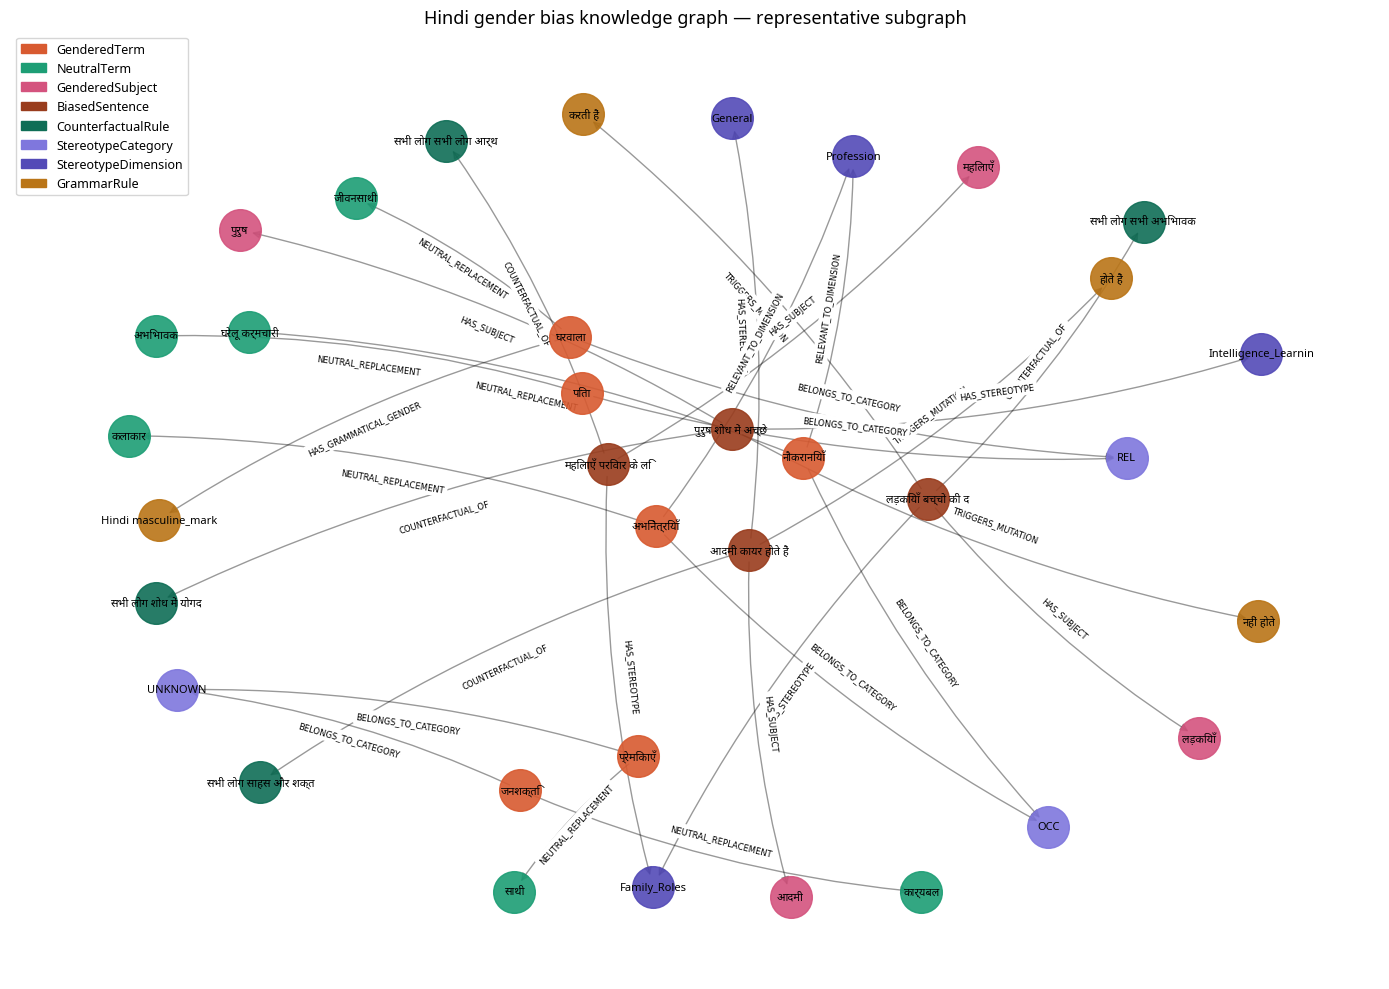

Saved static figure → /content/hindi_gender_kg/output/kg_subgraph_figure.png

Generating category/dimension breakdown chart...
CSP stereotype-dimension counts:
{'Emotion': 42, 'Intelligence_Learning': 66, 'General': 202, 'Family_Roles': 26, 'Behavior': 18}

GNP category counts:
{'OCC': 97, 'UNKNOWN': 116, 'REL': 43, 'REP': 40}


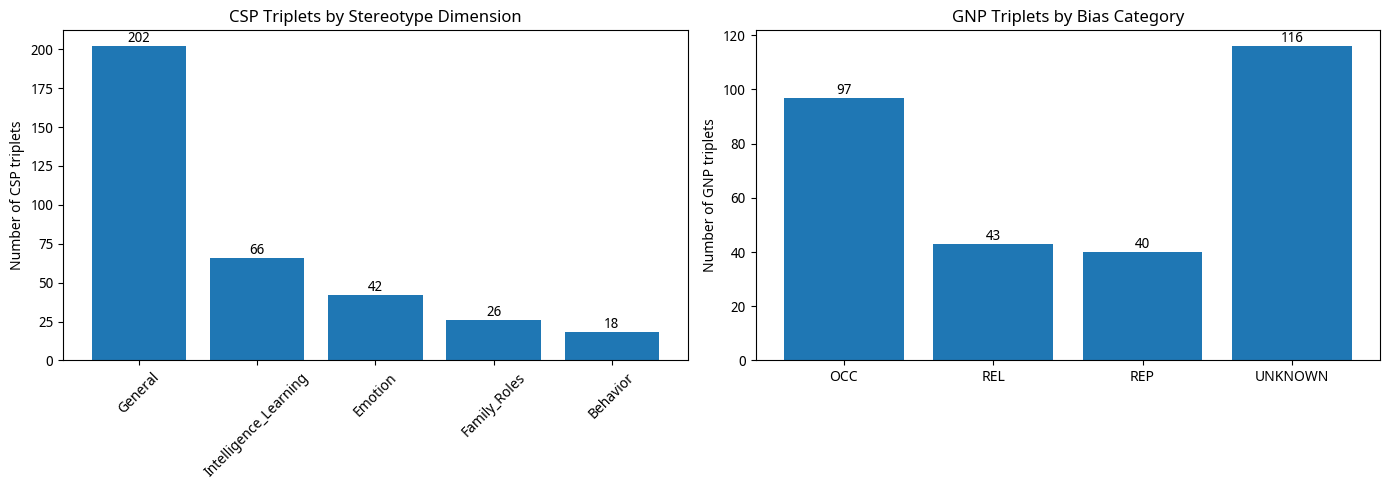


Chart saved to: /content/hindi_gender_kg/output/kg_breakdown_chart.png


In [15]:


if __name__ == "__main__":
    print("Loading KG...")
    G = nx.read_graphml(GRAPHML_PATH)
    with open(TRIPLETS_PATH, "r", encoding="utf-8") as f:
        triplets = json.load(f)

    print("Generating static subgraph figure...")
    plot_static_subgraph(G)

    print("\nGenerating category/dimension breakdown chart...")
    plot_category_breakdown(triplets)
